# Phase03

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import statsmodels.formula.api as smf

DATA_ROOT = Path("/Users/theocoronges/Documents/internship2026/data")
OD_DIR  = DATA_ROOT / "covid_comparison"
GEO_DIR = DATA_ROOT / "geometries"

PRE_OD  = OD_DIR / "pre_2020-02-14_2020-03-13"  / "Viajes_distritos_2020-02-14_2020-03-13_v1.parquet"
POST_OD = OD_DIR / "post_2023-02-14_2023-03-13" / "Viajes_distritos_2023-02-14_2023-03-13_v2.parquet"

# the two crosswalks: each translates one version's MITMA zone ids -> INE codes
V1_XWALK = GEO_DIR / "v1_relaciones_distrito_mitma.csv"        # v1 (2020) zones
V2_XWALK = GEO_DIR / "relacion_ine_zonificacionMitma.csv"      # v2 (2023) zones

# PRE runs 29 days (leap year) with a 5th Friday; drop it so both windows are
# 28 days = exactly 4 of every weekday, matching POST's day-of-week composition.
PRE_DROP_DATES = ["2020-02-14"]

## 2. Common-unit map

In [2]:
# reduce each crosswalk to: MITMA zone id -> set of INE municipalities
# drop rows with no INE municipality: they can't be placed on the common map
# (and a NaN muni would hang the union-find, since nan != nan)

# v1 file: columns are  distrito | distrito_mitma | municipio_mitma
#   `distrito` is a 7-digit INE district; its first 5 digits are the INE municipality.
v1 = pd.read_csv(V1_XWALK, sep="|", dtype=str)
v1["muni_ine"] = v1["distrito"].str[:5]
v1 = v1.dropna(subset=["muni_ine"])
v1_zone_munis = v1.groupby("distrito_mitma")["muni_ine"].apply(set)

# v2 file already carries the INE municipality directly in `municipio_ine`.
v2 = pd.read_csv(V2_XWALK, sep="|", dtype=str).dropna(subset=["municipio_ine"])
v2_zone_munis = v2.groupby("distrito_mitma")["municipio_ine"].apply(set)

print(f"v1 zones: {len(v1_zone_munis):,}   v2 zones: {len(v2_zone_munis):,}")
print("example v1 _AM zone 01001_AM covers munis:", sorted(v1_zone_munis['01001_AM']))

v1 zones: 2,850   v2 zones: 3,743
example v1 _AM zone 01001_AM covers munis: ['01001', '01009', '01013', '01021', '01027', '01053', '01061']


In [3]:
# union-find: merge municipalities that share a zone in EITHER year

class DisjointSet:
    """Groups items that must stay together. find(x) returns x's group label."""
    def __init__(self):
        self.parent = {}

    def find(self, x):
        self.parent.setdefault(x, x)          # first time we see x, it is its own group
        root = x
        while self.parent[root] != root:      # walk up to the group label
            root = self.parent[root]
        while self.parent[x] != root:         # path compression (keeps it fast)
            self.parent[x], x = root, self.parent[x]
        return root

    def union(self, a, b):
        self.parent[self.find(a)] = self.find(b)

groups = DisjointSet()
for muni_set in pd.concat([v1_zone_munis, v2_zone_munis]):
    munis = list(muni_set)
    first = munis[0]
    for other in munis:                       # registers every muni (incl. singletons)
        groups.union(first, other)            # and glues this zone's munis together

# a "common unit" is the group label of any municipality it contains
def zone_to_unit_map(zone_munis):
    return {zone: groups.find(next(iter(munis))) for zone, munis in zone_munis.items()}

v1_zone_to_unit = zone_to_unit_map(v1_zone_munis)   # v1 zone id -> common unit
v2_zone_to_unit = zone_to_unit_map(v2_zone_munis)   # v2 zone id -> common unit

n_munis = len({groups.find(m) for z in v1_zone_munis for m in z} |
              {groups.find(m) for z in v2_zone_munis for m in z})
print(f"common units (after merging forced groups): {n_munis:,}")

common units (after merging forced groups): 2,206


## 3. Trips → common units

In [4]:
def od_to_unit_pairs(parquet_path, zone_to_unit, split_weekend=False, exclude_dates=None):
    """One year's district OD -> per-day trip flows between common units.

    split_weekend=True keeps a `day_type` column (weekday/weekend) and normalises
    each slice by the number of days OF THAT TYPE in the window.
    exclude_dates drops given calendar days (used to balance the pre window).
    """
    od = pd.read_parquet(parquet_path, columns=["date", "id_origin", "id_destination", "n_trips"])
    dt = pd.to_datetime(od["date"])
    if exclude_dates:
        keep_day = ~dt.isin(pd.to_datetime(exclude_dates))
        od, dt = od[keep_day], dt[keep_day]

    # label each row weekday/weekend (also used to count days of each type)
    od["day_type"] = np.where(dt.dt.weekday >= 5, "weekend", "weekday")
    days_per_type = od.groupby("day_type")["date"].nunique()     # 20 weekday, 8 weekend
    slice_cols = ["day_type"] if split_weekend else []

    # sum over hours/days at the raw-zone level first (small result, light on memory)
    for col in ["id_origin", "id_destination"]:
        od[col] = od[col].astype("category")
    zone_pairs = od.groupby(slice_cols + ["id_origin", "id_destination"], observed=True,
                            as_index=False)["n_trips"].sum()
    del od

    # relabel both endpoints to the common unit
    zone_pairs["origin_unit"] = zone_pairs["id_origin"].astype(str).map(zone_to_unit)
    zone_pairs["dest_unit"]   = zone_pairs["id_destination"].astype(str).map(zone_to_unit)

    # drop foreign zones (no mapping) and within-unit trips (the artifact / undefined distance)
    keep = zone_pairs.dropna(subset=["origin_unit", "dest_unit"])
    keep = keep[keep["origin_unit"] != keep["dest_unit"]]

    # re-sum onto the common units and express as trips per day
    unit_pairs = keep.groupby(slice_cols + ["origin_unit", "dest_unit"],
                              as_index=False)["n_trips"].sum()
    per_day = unit_pairs["day_type"].map(days_per_type) if split_weekend else days_per_type.sum()
    unit_pairs["trips_per_day"] = unit_pairs["n_trips"] / per_day
    return unit_pairs


pre_pairs  = od_to_unit_pairs(PRE_OD,  v1_zone_to_unit, exclude_dates=PRE_DROP_DATES)
post_pairs = od_to_unit_pairs(POST_OD, v2_zone_to_unit)
print(f"pre  (2020): {len(pre_pairs):,} unit-pairs")
print(f"post (2023): {len(post_pairs):,} unit-pairs")

pre  (2020): 949,803 unit-pairs
post (2023): 1,163,200 unit-pairs


## 4. Fixed geometry per unit

In [5]:
districts = gpd.read_file(GEO_DIR / "distritos_2.geojson")          # id, population, geometry
districts["unit"] = districts["id"].map(v2_zone_to_unit)            # district -> common unit
districts["population"] = pd.to_numeric(districts["population"], errors="coerce")
districts = districts.dropna(subset=["unit"]).to_crs(25830)         # metres (mainland Spain)

# dissolve districts up to common units, sum their population
units = districts.dissolve(by="unit", aggfunc={"population": "sum"})

# fixed centroid per unit, in lon/lat (so distance can be geodesic, valid for the islands too)
centroid_ll = units.geometry.centroid.to_crs(4326)
units["lon"] = centroid_ll.x
units["lat"] = centroid_ll.y

# lookups by common-unit id
unit_lon = units["lon"]
unit_lat = units["lat"]
unit_pop = units["population"]
print(f"common units with geometry: {len(units):,}")

common units with geometry: 2,206


## 5. Gravity model (overall)

In [6]:
EARTH_KM = 6371.0088

def haversine_km(lon1, lat1, lon2, lat2):
    """Great-circle distance (km) — valid across UTM zones and out to the islands."""
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 2 * EARTH_KM * np.arcsin(np.sqrt(a))


def restrict_to_common(a, b, keys=("origin_unit", "dest_unit")):
    """Keep only origin->destination pairs seen in BOTH years, so v1/v2 differ only in
    flow size, not in which pairs each system happens to report (common support)."""
    keys = list(keys)
    shared = a[keys].merge(b[keys], on=keys)
    return a.merge(shared, on=keys), b.merge(shared, on=keys)


def build_model_frame(unit_pairs):
    """Attach distance + population to each unit-pair and take logs (ready for OLS)."""
    df = unit_pairs.copy()

    # fixed geodesic centroid distance (km)
    df["dist_km"] = haversine_km(df["origin_unit"].map(unit_lon), df["origin_unit"].map(unit_lat),
                                 df["dest_unit"].map(unit_lon),   df["dest_unit"].map(unit_lat))

    df["Pi"] = df["origin_unit"].map(unit_pop)   # origin population
    df["Pj"] = df["dest_unit"].map(unit_pop)     # destination population

    # keep only rows where logs are defined (positive everywhere)
    df = df.dropna(subset=["dist_km", "Pi", "Pj"])
    df = df[(df["trips_per_day"] > 0) & (df["dist_km"] > 0) & (df["Pi"] > 0) & (df["Pj"] > 0)]

    df["log_trips"] = np.log(df["trips_per_day"])
    df["log_Pi"]    = np.log(df["Pi"])
    df["log_Pj"]    = np.log(df["Pj"])
    df["log_dij"]   = np.log(df["dist_km"])
    return df


def fit_gravity(df):
    return smf.ols("log_trips ~ log_Pi + log_Pj + log_dij", data=df).fit()


def coefs(m):
    return {"n": int(m.nobs),
            "beta_Pi": m.params["log_Pi"],     # origin-population elasticity
            "beta_Pj": m.params["log_Pj"],     # destination-population elasticity
            "gamma":  -m.params["log_dij"],    # distance decay (sign flipped)
            "R2": m.rsquared}


# fit both years on the SAME set of pairs (common support)
pre_common, post_common = restrict_to_common(pre_pairs, post_pairs)
pre_model  = build_model_frame(pre_common)
post_model = build_model_frame(post_common)
print(f"common-support pairs: {len(pre_model):,}  (from pre {len(pre_pairs):,} / post {len(post_pairs):,})")

pre_fit  = fit_gravity(pre_model)
post_fit = fit_gravity(post_model)

common-support pairs: 702,544  (from pre 949,803 / post 1,163,200)


In [7]:
print("=" * 70, "\nPRE — 2020 (v1)\n", "=" * 70, sep="")
print(pre_fit.summary())
print("=" * 70, "\nPOST — 2023 (v2)\n", "=" * 70, sep="")
print(post_fit.summary())

PRE — 2020 (v1)
                            OLS Regression Results                            
Dep. Variable:              log_trips   R-squared:                       0.662
Model:                            OLS   Adj. R-squared:                  0.662
Method:                 Least Squares   F-statistic:                 4.580e+05
Date:                Wed, 01 Jul 2026   Prob (F-statistic):               0.00
Time:                        12:44:36   Log-Likelihood:            -1.1050e+06
No. Observations:              702544   AIC:                         2.210e+06
Df Residuals:                  702540   BIC:                         2.210e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.1903      0.016    

In [8]:
comparison = pd.DataFrame({"pre_2020": coefs(pre_fit),
                           "post_2023": coefs(post_fit)}).T
comparison["delta_gamma"] = comparison["gamma"] - comparison.loc["pre_2020", "gamma"]
comparison

,n,beta_Pi,beta_Pj,gamma,R2,delta_gamma
pre_2020,702544.0,0.562185,0.565510,1.853105,0.661689,0.000000
post_2023,702544.0,0.661213,0.658068,2.035378,0.705089,0.182274


## 6. Weekday vs weekend

In [9]:
# split flows by day type (same geometry / population / standardisation as section 5)
pre_wd  = od_to_unit_pairs(PRE_OD,  v1_zone_to_unit, split_weekend=True, exclude_dates=PRE_DROP_DATES)
post_wd = od_to_unit_pairs(POST_OD, v2_zone_to_unit, split_weekend=True)

rows = []
for day_type in ["weekday", "weekend"]:
    # common support computed within each day type
    a, b = restrict_to_common(pre_wd[pre_wd["day_type"] == day_type],
                              post_wd[post_wd["day_type"] == day_type])
    for year, sub in [("pre_2020", a), ("post_2023", b)]:
        m = fit_gravity(build_model_frame(sub))
        rows.append({"year": year, "day_type": day_type, **coefs(m)})

daytype_fits = pd.DataFrame(rows)
print(daytype_fits.round(3).to_string(index=False))

# gamma pre vs post for each day type, with the pre->post change
gamma_by_daytype = daytype_fits.pivot(index="day_type", columns="year", values="gamma")
gamma_by_daytype["delta_gamma"] = gamma_by_daytype["post_2023"] - gamma_by_daytype["pre_2020"]
gamma_by_daytype

     year day_type      n  beta_Pi  beta_Pj  gamma    R2
 pre_2020  weekday 592834    0.542    0.535  1.806 0.642
post_2023  weekday 592834    0.650    0.631  1.995 0.689
 pre_2020  weekend 397534    0.524    0.554  1.720 0.621
post_2023  weekend 397534    0.598    0.629  1.899 0.658


year,post_2023,pre_2020,delta_gamma
day_type,,,
weekday,1.995204,1.805852,0.189352
weekend,1.899307,1.720340,0.178967


## 7. Distance by district

In [10]:
def distance_by_origin(parquet_path):
    """Per origin district: trip-weighted average and median trip length (km)."""
    od = pd.read_parquet(parquet_path,
                         columns=["id_origin", "id_destination", "n_trips", "trips_total_length_km"])

    # collapse to OD pairs over the window; per-pair mean length = total km / trips
    pair = (od.groupby(["id_origin", "id_destination"], observed=True, as_index=False)
              [["n_trips", "trips_total_length_km"]].sum())
    pair = pair[pair["n_trips"] > 0]
    pair["dist_km"] = pair["trips_total_length_km"] / pair["n_trips"]

    # average = total km / total trips per origin
    g = pair.groupby("id_origin")
    avg = g["trips_total_length_km"].sum() / g["n_trips"].sum()

    # weighted median = first pair distance past half the origin's trips
    pair = pair.sort_values(["id_origin", "dist_km"])
    cum = pair.groupby("id_origin")["n_trips"].cumsum()
    tot = pair.groupby("id_origin")["n_trips"].transform("sum")
    med = pair[cum >= 0.5 * tot].groupby("id_origin")["dist_km"].first()

    out = pd.DataFrame({"avg_dist_km": avg, "median_dist_km": med})
    out.index.name = "district"
    return out


# v2 district population — shown alongside for comparison, NOT used in the distance calc
district_pop = pd.read_csv(GEO_DIR / "poblacion_distritos.csv", sep="|", header=None,
                           names=["district", "population"], dtype={"district": str})
district_pop = pd.to_numeric(district_pop.set_index("district")["population"], errors="coerce")

pre_dist  = distance_by_origin(PRE_OD)
post_dist = distance_by_origin(POST_OD)
post_dist["population"] = post_dist.index.map(district_pop)   # v2 ids only

print(f"pre  (2020): {len(pre_dist):,} districts   post (2023): {len(post_dist):,} districts")
print("\npre 2020 distance summary (km):")
print(pre_dist.describe().round(2).to_string())
post_dist.sort_values("population", ascending=False).head(10).round(2)

pre  (2020): 2,844 districts   post (2023): 3,855 districts

pre 2020 distance summary (km):
       avg_dist_km  median_dist_km
count       2844.0          2844.0
mean          14.0            6.78
std           8.04            5.05
min           2.35            0.92
25%           8.18            2.58
50%          11.93            5.41
75%          17.47            9.61
max          94.62           61.89


,avg_dist_km,median_dist_km,population
district,,,
0801902,7.62,2.25,264353.0
2807911,5.79,1.93,258064.0
2807908,7.82,2.43,247327.0
2807910,6.31,2.42,239693.0
2807913,5.79,1.81,238577.0
0801910,5.38,1.79,238245.0
2807915,7.01,2.04,216400.0
2807916,7.39,3.13,192809.0
0801903,12.19,2.29,184367.0


Spearman correlation with population (rho, p-value):
  avg_dist_km      rho=-0.544  p=2.31e-287  (n=3,737)
  median_dist_km   rho=-0.553  p=1.28e-298  (n=3,737)


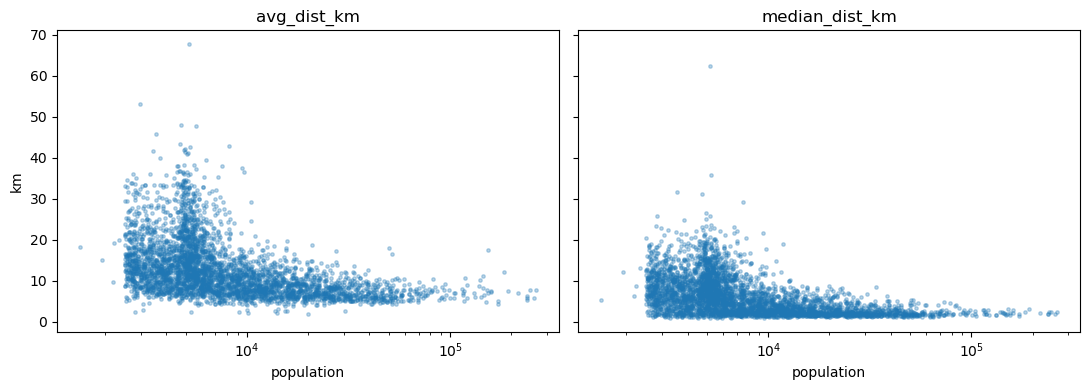

In [11]:
# compare population with distance (post 2023, where district population is defined)
from scipy.stats import spearmanr

cmp = post_dist.dropna(subset=["population"])
print("Spearman correlation with population (rho, p-value):")
for col in ["avg_dist_km", "median_dist_km"]:
    rho, p = spearmanr(cmp["population"], cmp[col])
    print(f"  {col:15s}  rho={rho:+.3f}  p={p:.2e}  (n={len(cmp):,})")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, col in zip(ax, ["avg_dist_km", "median_dist_km"]):
    a.scatter(cmp["population"], cmp[col], s=6, alpha=0.3)
    a.set_xscale("log"); a.set_xlabel("population"); a.set_title(col)
ax[0].set_ylabel("km")
plt.tight_layout()

## 8. POIs vs population (March 2025)

In [12]:
REC_OD   = DATA_ROOT / "recent_2025-03" / "Viajes_distritos_2025-03_v2.parquet"
POI_FILE = DATA_ROOT / "poi" / "fsq_places_spain.parquet"

# native v2 district geometry: fixed centroid per district in lon/lat (for geodesic distance)
gdf = gpd.read_file(GEO_DIR / "distritos_2.geojson")[["id", "geometry"]].to_crs(25830)
cent = gdf.set_index("id").geometry.centroid.to_crs(4326)
dist_lon, dist_lat = cent.x, cent.y

# population per district
district_pop = pd.read_csv(GEO_DIR / "poblacion_distritos.csv", sep="|", header=None,
                           names=["district", "population"], dtype={"district": str})
district_pop = pd.to_numeric(district_pop.set_index("district")["population"], errors="coerce")

# POIs per district (Foursquare OS Places, Spain, 2026-06 release) by point-in-polygon
poi = pd.read_parquet(POI_FILE)
poi = gpd.GeoDataFrame(poi, geometry=gpd.points_from_xy(poi["longitude"], poi["latitude"]),
                       crs=4326).to_crs(25830)
district_pois = (gpd.sjoin(poi, gdf, predicate="within", how="inner")
                    .groupby("id").size().reindex(gdf["id"]).fillna(0).astype(int))
district_pois.index.name = "district"
print(f"Spain POIs: {len(poi):,}   districts with >=1 POI: {(district_pois > 0).sum():,}/{len(gdf):,}")

Spain POIs: 1,925,251   districts with >=1 POI: 3,754/3,792


In [13]:
def od_pairs_district(parquet_path):
    """Month of district OD -> per-day flows between distinct districts."""
    od = pd.read_parquet(parquet_path, columns=["date", "id_origin", "id_destination", "n_trips"])
    n_days = od["date"].nunique()
    for c in ["id_origin", "id_destination"]:
        od[c] = od[c].astype("category")          # 109M rows -> keep the groupby light
    pairs = od.groupby(["id_origin", "id_destination"], observed=True, as_index=False)["n_trips"].sum()
    pairs["id_origin"] = pairs["id_origin"].astype(str)
    pairs["id_destination"] = pairs["id_destination"].astype(str)
    pairs = pairs[pairs["id_origin"] != pairs["id_destination"]]   # drop within-district
    pairs["trips_per_day"] = pairs["n_trips"] / n_days
    return pairs


rec_pairs = od_pairs_district(REC_OD)
print(f"March 2025: {len(rec_pairs):,} district pairs")

March 2025: 3,359,772 district pairs


In [14]:
def build_mass_frame(pairs):
    """District pairs + centroid distance + both masses (population, POIs), logged.
    Same row set for every fit, so R2 / AIC / gamma are directly comparable."""
    df = pairs.copy()
    df["dist_km"] = haversine_km(df["id_origin"].map(dist_lon), df["id_origin"].map(dist_lat),
                                 df["id_destination"].map(dist_lon), df["id_destination"].map(dist_lat))
    df["pop_i"] = df["id_origin"].map(district_pop);  df["pop_j"] = df["id_destination"].map(district_pop)
    df["poi_i"] = df["id_origin"].map(district_pois); df["poi_j"] = df["id_destination"].map(district_pois)

    cols = ["dist_km", "pop_i", "pop_j", "poi_i", "poi_j"]
    df = df.dropna(subset=cols)
    df = df[(df["trips_per_day"] > 0) & (df[cols] > 0).all(axis=1)]

    df["log_trips"] = np.log(df["trips_per_day"]);  df["log_dij"] = np.log(df["dist_km"])
    for c in ["pop_i", "pop_j", "poi_i", "poi_j"]:
        df["log_" + c] = np.log(df[c])
    return df


rec_model = build_mass_frame(rec_pairs)

# baseline: population at both ends.  POI model: population generates (origin i),
# POIs attract (destination j).  Both fit on the SAME rows -> R2/AIC/gamma comparable.
m_pop = smf.ols("log_trips ~ log_pop_i + log_pop_j + log_dij", data=rec_model).fit()
m_poi = smf.ols("log_trips ~ log_pop_i + log_poi_j + log_dij", data=rec_model).fit()


def mass_coefs(m, i_term, j_term):
    return {"n": int(m.nobs),
            "beta_i":  m.params[i_term],     # origin-mass elasticity
            "beta_j":  m.params[j_term],     # destination-mass elasticity
            "gamma":  -m.params["log_dij"],  # distance decay
            "R2": m.rsquared, "AIC": m.aic}


pd.DataFrame({"population (pop_i, pop_j)":     mass_coefs(m_pop, "log_pop_i", "log_pop_j"),
              "poi-attraction (pop_i, poi_j)": mass_coefs(m_poi, "log_pop_i", "log_poi_j")}).T

,n,beta_i,beta_j,gamma,R2,AIC
"population (pop_i, pop_j)",3126370.0,0.526378,0.530398,1.586328,0.661265,9.706805e+06
"poi-attraction (pop_i, poi_j)",3126370.0,0.529114,0.464991,1.600702,0.664853,9.673511e+06


## 9. Distance by district vs POIs (March 2025)

March 2025 distance-by-district — Spearman (rho, p-value):
  avg_dist_km     vs n_pois       rho=-0.438  p=3.18e-175  (n=3,742)
  median_dist_km  vs n_pois       rho=-0.502  p=1.37e-238  (n=3,742)
  avg_dist_km     vs population   rho=-0.539  p=1.84e-281  (n=3,742)
  median_dist_km  vs population   rho=-0.551  p=2.00e-296  (n=3,742)


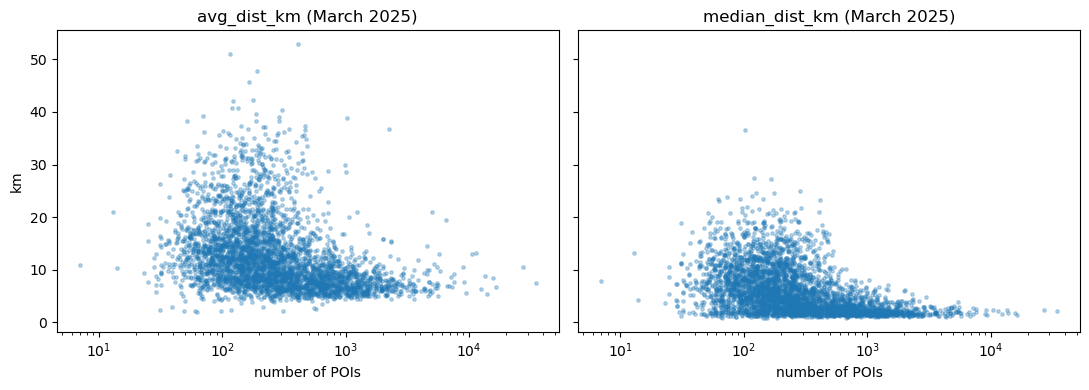

In [15]:
# reuse distance_by_origin() from section 7 on the recent month
rec_dist = distance_by_origin(REC_OD)
rec_dist["population"] = rec_dist.index.map(district_pop)
rec_dist["n_pois"]     = rec_dist.index.map(district_pois)

from scipy.stats import spearmanr
print("March 2025 distance-by-district — Spearman (rho, p-value):")
for mass in ["n_pois", "population"]:
    c = rec_dist.dropna(subset=[mass]); c = c[c[mass] > 0]
    for col in ["avg_dist_km", "median_dist_km"]:
        rho, p = spearmanr(c[mass], c[col])
        print(f"  {col:15s} vs {mass:11s}  rho={rho:+.3f}  p={p:.2e}  (n={len(c):,})")

# scatter vs POIs (the new mass of interest)
c = rec_dist[rec_dist["n_pois"] > 0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, col in zip(ax, ["avg_dist_km", "median_dist_km"]):
    a.scatter(c["n_pois"], c[col], s=6, alpha=0.3)
    a.set_xscale("log"); a.set_xlabel("number of POIs"); a.set_title(col + " (March 2025)")
ax[0].set_ylabel("km"); plt.tight_layout()